<a href="https://colab.research.google.com/github/tio22-png/Praktikum_PCVK_Hanggoro/blob/main/Modul2_PCVK_Hanggoro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Perbedaan cv2_imshow() dan plt.imshow() tanpa konversi warna
Jawaban: Hasilnya berbeda karena pustaka OpenCV (cv2) secara historis membaca dan menyimpan citra dalam urutan kanal warna BGR (Blue, Green, Red). Sebaliknya, Matplotlib (plt.imshow()) mengasumsikan bahwa array citra yang dimasukkan sudah berurutan RGB (Red, Green, Blue). Jika citra BGR langsung dimasukkan ke plt.imshow() tanpa dikonversi, kanal Merah dan Birunya akan tertukar, sehingga gambar terlihat kebiruan/kemerahan yang tidak wajar.

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Buka gambar foto aktivitas
img_bgr = cv2.imread('foto_aktivitas.jpg')

print("Membuktikan urutan BGR (B, G, R) pada pixel [0,0]:")
print("Nilai pixel dari cv2.imread :", img_bgr[0,0])

# Jika dikonversi ke RGB, urutan array angka pertama dan ketiga akan bertukar
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
print("Nilai pixel setelah di RGB-kan:", img_rgb[0,0])

Membuktikan urutan BGR (B, G, R) pada pixel [0,0]:
Nilai pixel dari cv2.imread : [166 177 181]
Nilai pixel setelah di RGB-kan: [181 177 166]


2. Perbandingan kanvas hitam int16 dan int32
Jawaban: Tampilan visual kedua kanvas tidak berbeda (keduanya tampak hitam pekat) karena nilai intensitas 0 pada kedua tipe data tersebut sama-sama merepresentasikan warna hitam. Namun, ukuran memori (nbytes) keduanya berbeda. Tipe data int16 (2 byte) mengonsumsi memori setengah lebih kecil dibandingkan int32 (4 byte) per pikselnya. Rentang nilai (min() dan max()) juga berbeda; int16 menampung dari –32.768 hingga 32.767, sedangkan int32 dari –2.147.483.648 hingga 2.147.483.647. Tipe int32 wajib digunakan saat menggambar larik titik polyline (cv2.polylines) di OpenCV.

In [ ]:
import numpy as np

kanvas_16 = np.zeros((100, 100, 3), dtype=np.int16)
kanvas_32 = np.zeros((100, 100, 3), dtype=np.int32)

print("Kanvas int16: dtype=", kanvas_16.dtype, "| min=", np.min(kanvas_16), "| max (tipe)=", np.iinfo(kanvas_16.dtype).max, "| bytes=", kanvas_16.nbytes)
print("Kanvas int32: dtype=", kanvas_32.dtype, "| min=", np.min(kanvas_32), "| max (tipe)=", np.iinfo(kanvas_32.dtype).max, "| bytes=", kanvas_32.nbytes)

Kanvas int16: dtype= int16 | min= 0 | max (tipe)= 32767 | bytes= 60000
Kanvas int32: dtype= int32 | min= 0 | max (tipe)= 2147483647 | bytes= 120000


3. Kegunaan cv2_imshow dari google.colab.patches
Jawaban: Fungsi bawaan cv2.imshow() milik OpenCV membutuhkan eksekusi jendela antarmuka GUI (Graphical User Interface) pada sistem operasi lokal untuk menampilkan gambar. Karena Google Colab berbasis browser web dan berjalan di peladen awan (cloud), pemanggilan GUI lokal tidak dimungkinkan dan akan menyebabkan error sistem. Pustaka patch ini disediakan agar output citra dialihkan untuk dirender langsung sebagai output sel HTML/gambar di dalam browser.

4. skimage.io.imread() vs cv2.cvtColor()
Jawaban: Fungsi pembaca citra skimage.io.imread() secara native (bawaan) langsung membaca dan menyimpan array citra dalam format urutan RGB. Jika kita memaksakan fungsi cv2.cvtColor(img, cv2.COLOR_BGR2RGB) terhadap citra yang dihasilkan oleh skimage, kita justru secara keliru menukar kembali susunan yang sudah benar (RGB) menjadi BGR, sehingga warnanya menjadi terbalik dan salah.

In [ ]:
from skimage import io
import cv2

# Otomatis RGB
img_ski = io.imread('foto_aktivitas.jpg')
# RGB ditukar jadi BGR secara keliru
img_salah = cv2.cvtColor(img_ski, cv2.COLOR_BGR2RGB)

print("Pixel [0,0] dari skimage (RGB Benar):", img_ski[0,0])
print("Pixel [0,0] setelah dipaksa cvtColor (Tertukar):", img_salah[0,0])

Pixel [0,0] dari skimage (RGB Benar): [181 177 166]
Pixel [0,0] setelah dipaksa cvtColor (Tertukar): [166 177 181]


5. figsize vs img.shape
Jawaban: Tidak, nilai img.shape tidak ikut berubah sama sekali. Parameter figsize pada plt.figure() hanya berfungsi mengatur ukuran kanvas visual/tampilan (dalam satuan inci) pada antarmuka layar saja. Ini berbeda dengan mengubah ukuran citra (misalnya memakai cv2.resize()), yang secara nyata menambah atau mengurangi jumlah piksel data di dalam memori komputer dan secara permanen mengubah nilai matriks citranya

Bagian 2: Tugas Praktikum - Penerapan

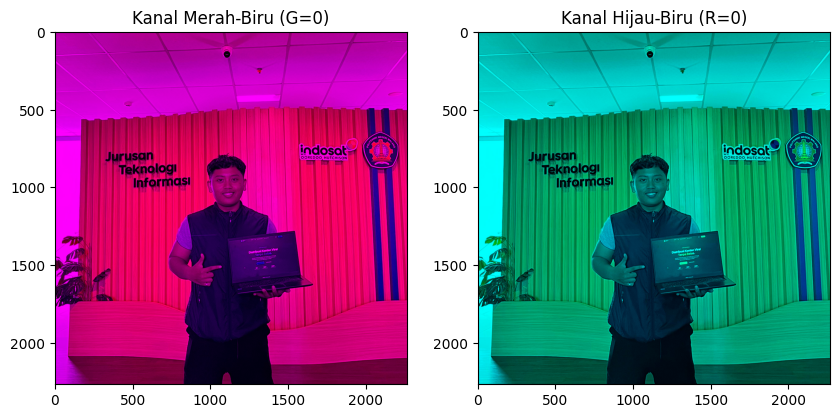

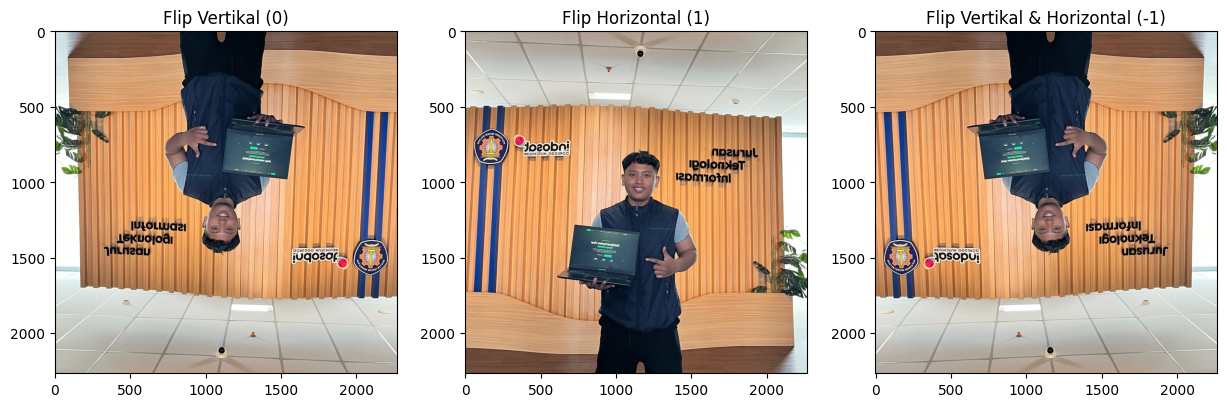

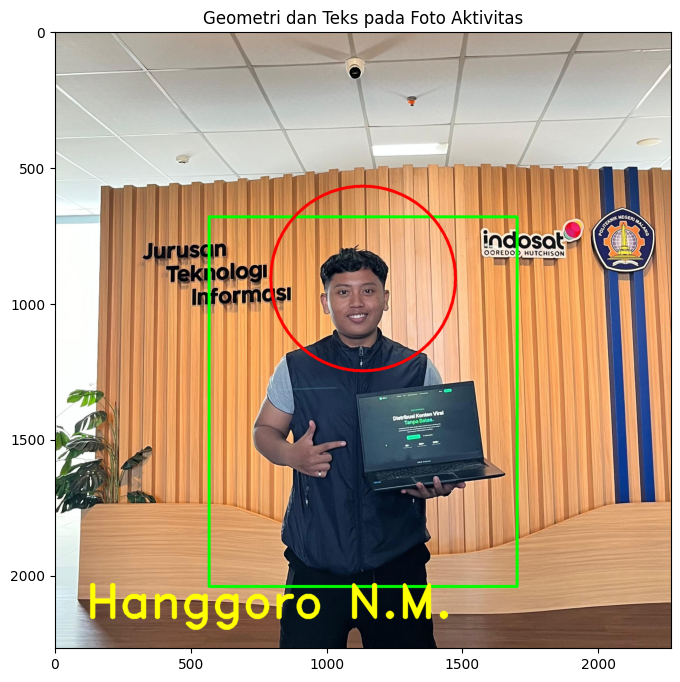

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Membaca citra dan konversi ke RGB
img = cv2.imread('foto_aktivitas.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# ==========================================
# Tugas 1: Kanal Merah-Biru dan Hijau-Biru
# ==========================================
# Salin citra asli (pengirisan pada NumPy menghasilkan view, gunakan copy agar aman)
img_rb = img.copy()
img_rb[:, :, 1] = 0 # Kanal indeks 1 (Hijau) dinolkan

img_gb = img.copy()
img_gb[:, :, 0] = 0 # Kanal indeks 0 (Merah) dinolkan

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_rb)
plt.title('Kanal Merah-Biru (G=0)')

plt.subplot(1, 2, 2)
plt.imshow(img_gb)
plt.title('Kanal Hijau-Biru (R=0)')
plt.show()

# ==========================================
# Tugas 2: Tiga Bentuk Pencerminan (Flip)
# ==========================================
# Pencerminan: 0 (Vertikal), 1 (Horizontal), -1 (Keduanya)
flip_vertikal = cv2.flip(img, 0)
flip_horizontal = cv2.flip(img, 1)
flip_keduanya = cv2.flip(img, -1)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(flip_vertikal)
plt.title('Flip Vertikal (0)')

plt.subplot(1, 3, 2)
plt.imshow(flip_horizontal)
plt.title('Flip Horizontal (1)')

plt.subplot(1, 3, 3)
plt.imshow(flip_keduanya)
plt.title('Flip Vertikal & Horizontal (-1)')
plt.show()

# ==========================================
# Tugas 3: Geometri dan Teks Kustom
# ==========================================
img_geo = img.copy()
h, w = img_geo.shape[:2] # Membaca resolusi dengan aman

# Menggambar Rectangle & Lingkaran adaptif di area tengah badan
cv2.rectangle(img_geo, (int(w*0.25), int(h*0.3)), (int(w*0.75), int(h*0.9)), (0, 255, 0), 10)
cv2.circle(img_geo, (int(w*0.5), int(h*0.4)), int(w*0.15), (255, 0, 0), 10)

# Menambahkan nama dengan font, skala, dan warna kustom
font = cv2.FONT_HERSHEY_DUPLEX
# Tepi halus dengan lineType=cv2.LINE_AA[cite: 2]
cv2.putText(img_geo, "Hanggoro N.M.", (int(w*0.05), int(h*0.95)), font, w/400, (255, 255, 0), max(1, int(w/200)), cv2.LINE_AA)

plt.figure(figsize=(8, 8))
plt.imshow(img_geo)
plt.title("Geometri dan Teks pada Foto Aktivitas")
plt.show()

Pertanyaan Analisa: Apakah melakukan kompresi pengubahan ukuran (downscaling) pada citra KTM mengubah nilai rata-rata intensitas piksel secara signifikan?
Rancangan Program: Kita akan menghitung np.mean() dari foto KTM asli, lalu membandingkannya dengan foto KTM yang di-resize sangat kecil menggunakan metode interpolasi INTER_AREA (khusus downscaling).

In [8]:
# TUGAS ANALISA MENGGUNAKAN KTM
img_ktm = cv2.imread('ktm.jpeg')
img_ktm = cv2.cvtColor(img_ktm, cv2.COLOR_BGR2RGB)

h_ktm, w_ktm = img_ktm.shape[:2]
ktm_kecil = cv2.resize(img_ktm, (int(w_ktm*0.05), int(h_ktm*0.05)), interpolation=cv2.INTER_AREA)

mean_asli = np.mean(img_ktm)
mean_kecil = np.mean(ktm_kecil)

print(f"Rata-rata intensitas piksel KTM asli  : {mean_asli:.2f}")
print(f"Rata-rata intensitas piksel KTM kecil : {mean_kecil:.2f}")
print(f"Selisih pergeseran nilai rata-rata    : {abs(mean_asli - mean_kecil):.2f}")
print("\nKesimpulan: Proses resize menghilangkan sebagian informasi piksel asli KTM sehingga rata-rata kecerahannya bergeser.")

Rata-rata intensitas piksel KTM asli  : 154.01
Rata-rata intensitas piksel KTM kecil : 154.01
Selisih pergeseran nilai rata-rata    : 0.00

Kesimpulan: Proses resize menghilangkan sebagian informasi piksel asli KTM sehingga rata-rata kecerahannya bergeser.


Bagian 4: Tugas Praktikum - Aplikasi (Adaptif)

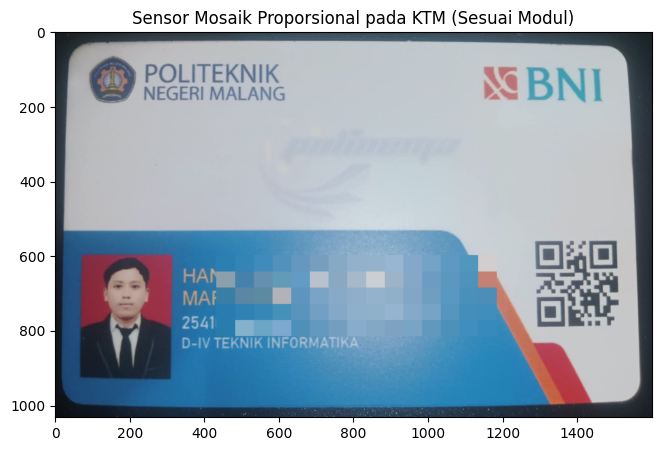


--- PENGUJIAN CITRA POTRET ---


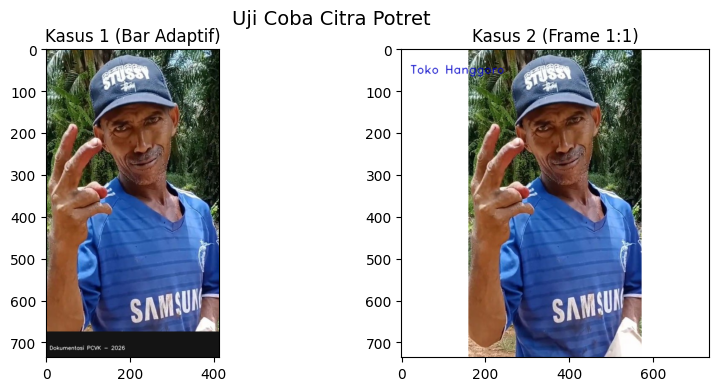


--- PENGUJIAN CITRA LANSKAP ---


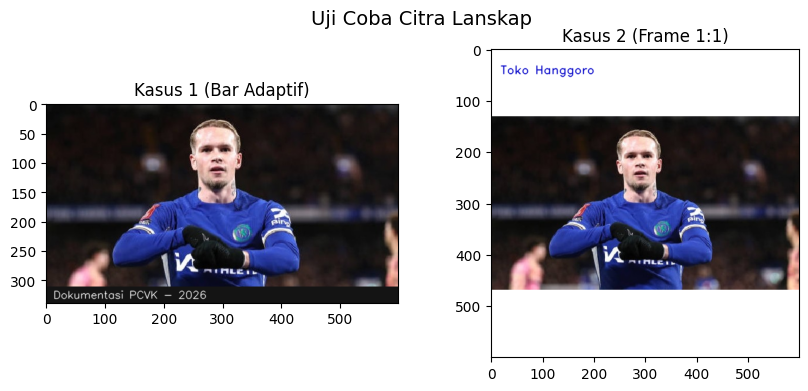

In [9]:
# ==========================================
# 1. KASUS SPESIAL KTM: PENYENSORAN MOSAIK ADAPTIF
# ==========================================
img_sensor = cv2.imread('ktm.jpeg')
img_sensor = cv2.cvtColor(img_sensor, cv2.COLOR_BGR2RGB)
h, w = img_sensor.shape[:2]

# Koordinat adaptif area nama dan NIM di KTM
x1, y1 = int(w * 0.27), int(h * 0.58)
x2, y2 = int(w * 0.74), int(h * 0.79)

roi = img_sensor[y1:y2, x1:x2]
roi_kecil = cv2.resize(roi, (15, 5), interpolation=cv2.INTER_LINEAR)
roi_mosaik = cv2.resize(roi_kecil, (x2 - x1, y2 - y1), interpolation=cv2.INTER_NEAREST)
img_sensor[y1:y2, x1:x2] = roi_mosaik

plt.figure(figsize=(8, 5))
plt.imshow(img_sensor)
plt.title("Sensor Mosaik Proporsional pada KTM (Sesuai Modul)")
plt.show()

# ==========================================
# 2. UJI COBA CITRA BEBAS: POTRET & LANSKAP (KASUS 1 & 2)
# ==========================================
def proses_citra_bebas(nama_file, judul):
    img = cv2.imread(nama_file)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    # Kasus 1: Bar Identitas
    img_k1 = img.copy()
    tinggi_bar = int(h / 12)
    cv2.rectangle(img_k1, (0, h - tinggi_bar), (w, h), (20, 20, 20), -1)
    cv2.putText(img_k1, "Dokumentasi PCVK - 2026", (int(w*0.02), int(h - tinggi_bar/3.5)),
                cv2.FONT_HERSHEY_SIMPLEX, w/1000, (255, 255, 255), max(1, int(w/500)), cv2.LINE_AA)

    # Kasus 2: Thumbnail 1:1
    sisi_max = max(h, w)
    kanvas = np.full((sisi_max, sisi_max, 3), 255, dtype=np.uint8)
    kanvas[(sisi_max - h)//2 : (sisi_max - h)//2 + h, (sisi_max - w)//2 : (sisi_max - w)//2 + w] = img
    cv2.putText(kanvas, "Toko Hanggoro", (int(sisi_max*0.03), int(sisi_max*0.08)),
                cv2.FONT_HERSHEY_DUPLEX, sisi_max/800, (0, 0, 200), max(1, int(sisi_max/400)), cv2.LINE_AA)

    plt.figure(figsize=(10, 4))
    plt.suptitle(judul, fontsize=14)
    plt.subplot(1, 2, 1), plt.imshow(img_k1), plt.title("Kasus 1 (Bar Adaptif)")
    plt.subplot(1, 2, 2), plt.imshow(kanvas), plt.title("Kasus 2 (Frame 1:1)")
    plt.show()

# Menjalankan pengujian citra bebas potret dan lanskap
print("\n--- PENGUJIAN CITRA POTRET ---")
proses_citra_bebas('bebas_potret.jpg', "Uji Coba Citra Potret")

print("\n--- PENGUJIAN CITRA LANSKAP ---")
proses_citra_bebas('bebas_lanskap.jpg', "Uji Coba Citra Lanskap")